In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans
from sklearn.preprocessing import LabelEncoder

In [2]:
df = pd.read_csv('Grocery.csv')
df.head()

,Product,Category,Price,Quantity
0,Bread,Food,20,2
1,Milk,Food,60,5
2,Biscuit,Food,20,2
3,Bourn-Vita,Food,70,1
4,Maggi,Food,20,5


/lib/python3.13/site-packages/threadpoolctl.py:1123: RuntimeWarning: JsProxy.as_object_map() is deprecated. Use as_py_json() instead.
  for filepath in LDSO.loadedLibsByName.as_object_map():


Cluster Labels: 
[0 2 0 2 0 2 0 0 2 2 1 2 0 0 1 2 1 0 2 0]


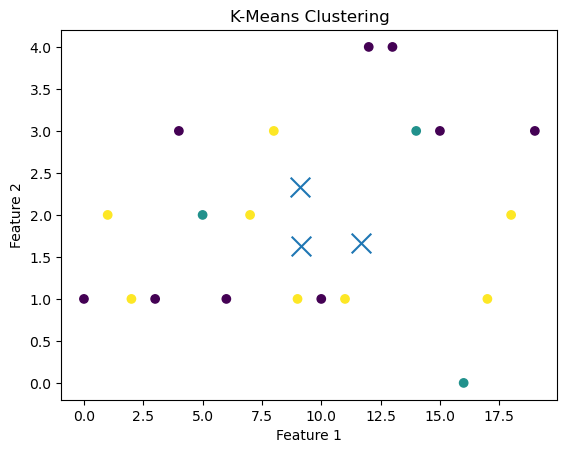

In [6]:
for col in df.columns:
    if df[col].dtype == 'object':
        df[col] = LabelEncoder().fit_transform(df[col])

model = KMeans(
    n_clusters = 3,
    random_state = 42
)
model.fit(df)
clusters = model.labels_
print(f'Cluster Labels: \n{clusters}')

df['cluster'] = clusters
df.head()

plt.scatter(
    df.iloc[:, 0],
    df.iloc[:, 1],
    c = clusters
)

plt.scatter(
    model.cluster_centers_[:, 0],
    model.cluster_centers_[:, 1],
    marker = 'x',
    s = 200
)

plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.title('K-Means Clustering')
plt.show()